<a href="https://colab.research.google.com/github/RSChaudhary-art/Time-Series-Analysis/blob/main/Copy_of_Thakmarpha_Tmin_forecasting_apple_frost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thakmarpha (Mustang, Nepal) daily minimum temperature: time-series forecasting for apple frost-risk decisions
**Station:** Thakmarpha, index 0604, 28.7409 N, 83.70 E, Elevation- 2655 m.
**Data:** manual daily minimum air temperature, 15 Mar 1996 to 2 Nov 2026.

This notebook is fully self-contained and uses only NumPy, SciPy, pandas and matplotlib (all pre-installed in Google Colab).
The classical models (MA, AR, ARIMA, SARIMA-type) and the neural networks (RNN, LSTM, quantile-LSTM) are implemented from scratch,
so every number in the report can be reproduced by running this notebook top to bottom.

**Honesty note:** the workbook contains temperature only. No apple yield or phenology data were supplied, so the notebook cannot
measure the *effect* of temperature on yield. It forecasts next-day minimum temperature and turns the forecast into a frost-protection decision.

In [ ]:
import os, json, math, time, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats, optimize, signal
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'axes.spines.top':False,'axes.spines.right':False})
os.makedirs('figures',exist_ok=True)
RES={}   # every number that goes into the report is stored here and written to results.json at the end
def savefig(name):
    plt.tight_layout(); plt.savefig(f'figures/{name}.png',dpi=150); plt.show()

In [ ]:
# ---------- 1. Load data ----------
FILE='Thakmarpha__Time_series_anlysis__Dail_minimum_Temperature.xlsx'
SEARCH=[FILE,'/mnt/user-data/uploads/'+FILE,'/content/'+FILE]
path=next((p for p in SEARCH if os.path.exists(p)),None)
if path is None:                       # Google Colab: ask for the upload
    from google.colab import files
    up=files.upload(); path=list(up.keys())[0]
d=pd.read_excel(path,sheet_name=0); d.columns=['time','year_formula','tmin']
st=pd.read_excel(path,sheet_name='Stations'); print(st.to_string(index=False))
d['date']=pd.to_datetime(d['time'],format='%m/%d/%Y %H:%M:%S').dt.normalize()
assert d.date.is_monotonic_increasing and not d.date.duplicated().any()
raw=d.set_index('date')['tmin'].reindex(pd.date_range(d.date.min(),d.date.max(),freq='D')); raw.index.name='date'
RES['n_days']=len(raw); RES['start']=str(raw.index[0].date()); RES['end']=str(raw.index[-1].date())
RES['n_rows_in_file']=int(len(d)); RES['n_missing']=int(raw.isna().sum())
print(RES)
print('values not on a 0.5 degC grid:',int((d.tmin.dropna()%0.5!=0).sum()))

Saving Thakmarpha, Time series anlysis, Dail minimum Temperature.xlsx to Thakmarpha, Time series anlysis, Dail minimum Temperature.xlsx
 Station Index       Name District  Latitude  Longitude  Elevation
           604 Thakmarpha  MUSTANG 28.740909       83.7       2655
{'n_days': 11190, 'start': '1996-03-15', 'end': '2026-11-02', 'n_rows_in_file': 11173, 'n_missing': 41}
values not on a 0.5 degC grid: 407


observed       11149
climatology       30
linear            11
Name: count, dtype: int64
flag
climatology    (2000-09-17, 2000-10-16)
linear         (1999-10-20, 2009-12-31)
dtype: object


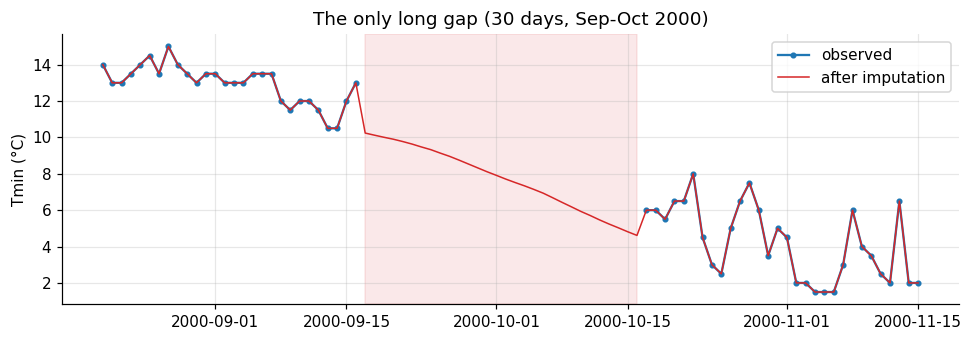

RMSE of climatology-based filling on observed days (every 7th day): 2.1 degC


In [ ]:
# ---------- 2. Imputation ----------
# Rule requested: gaps of 1-2 days -> linear interpolation; longer gaps -> day-of-year climatology (+/-14 days, other years only).
def doy365(idx):
    di=idx.dayofyear.values.copy()
    di=np.where(idx.is_leap_year&(idx.month>2),di-1,di); di=np.where((idx.month==2)&(idx.day==29),59,di)
    return di
gap=raw.isna(); run_id=(gap!=gap.shift()).cumsum(); run_len=gap.groupby(run_id).transform('size')*gap
short=(run_len>0)&(run_len<=2); long_=run_len>2
RES['gap_runs']={int(k):int(v) for k,v in pd.Series(run_len[run_len>0].groupby(run_id[run_len>0]).first()).value_counts().items()}
x=raw.copy(); lin=raw.interpolate(method='linear',limit_area='inside'); x[short]=lin[short]
od=doy365(raw.index); oy=raw.index.year.values; v=raw.values
for i in np.where(long_.values)[0]:
    dd=np.abs(od-od[i]); dd=np.minimum(dd,365-dd)
    m=(dd<=14)&(oy!=oy[i])&~np.isnan(v)          # observed values only, other years only
    x.iloc[i]=v[m].mean()
flag=pd.Series(np.where(short,'linear',np.where(long_,'climatology','observed')),index=raw.index)
RES['n_linear']=int(short.sum()); RES['n_clim']=int(long_.sum()); RES['pct_imputed']=round(100*(short.sum()+long_.sum())/len(raw),3)
assert x.isna().sum()==0
imp=pd.DataFrame({'tmin_raw':raw,'tmin_imputed':x,'flag':flag}); imp.to_csv('thakmarpha_tmin_imputed.csv')
print(flag.value_counts()); print(imp[imp.flag!='observed'].groupby('flag').apply(lambda g:(g.index.min().date(),g.index.max().date())))
y=x.copy()   # complete series used for everything below
gi=imp.index[imp.flag=='climatology']
fig,ax=plt.subplots(figsize=(9,3.2)); w=imp.loc['2000-08-20':'2000-11-15']
ax.plot(w.index,w.tmin_raw,'o-',ms=3,label='observed'); ax.plot(w.index,w.tmin_imputed,'-',color='C3',lw=1,label='after imputation')
ax.axvspan(gi.min(),gi.max(),color='C3',alpha=.1); ax.set_ylabel('Tmin (°C)'); ax.legend(); ax.set_title('The only long gap (30 days, Sep-Oct 2000)')
savefig('fig01_gap')
# one-step check of the climatology method: leave-one-out error of the +/-14 d climatology on observed days (shows how much a filled day can be wrong)
obs=~raw.isna().values; idxs=np.where(obs)[0][::7]; err=[]
for i in idxs:
    dd=np.abs(od-od[i]); dd=np.minimum(dd,365-dd); m=(dd<=14)&(oy!=oy[i])&obs; err.append(v[i]-v[m].mean())
err=np.array(err); RES['clim_impute_rmse']=float(np.sqrt(np.mean(err**2))); RES['clim_impute_sd_obs']=float(np.nanstd(v))
print('RMSE of climatology-based filling on observed days (every 7th day):',round(RES['clim_impute_rmse'],2),'degC')

## Task 2 - Decomposition, autocorrelation
Additive classical decomposition: trend = centred 365-day moving average, seasonal = day-of-year mean of the detrended series,
remainder = what is left. Descriptive only (uses all years); model selection later uses the training period only.

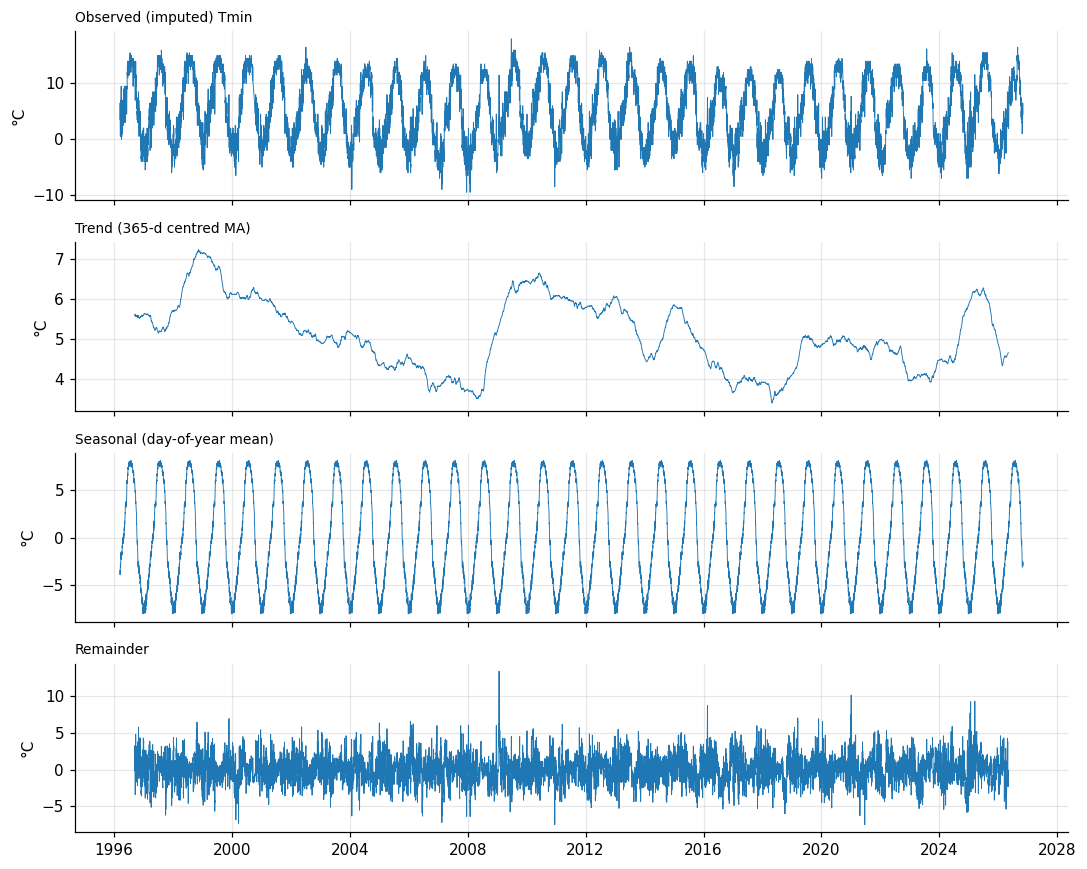

{'var_total': 34.17038491320749, 'var_seasonal': 30.014345508745123, 'var_trend': 0.7467168817852451, 'var_remainder': 3.326753331754412, 'seasonal_strength': 0.9002206451662185, 'trend_strength': 0.19566214748673283, 'seasonal_range': 16.230733701967562, 'share_var_seasonal': 0.8780996261129302}
Ljung-Box(20) on decomposition remainder: Q=9792 p=0


In [ ]:
trend=y.rolling(365,center=True,min_periods=365).mean()
detr=y-trend
seas_doy=detr.groupby(doy365(detr.index)).mean(); seas_doy=seas_doy-seas_doy.mean()
seasonal=pd.Series(seas_doy.reindex(doy365(y.index)).values,index=y.index)
remainder=y-trend-seasonal
fig,ax=plt.subplots(4,1,figsize=(10,8),sharex=True)
for a,s,t in zip(ax,[y,trend,seasonal,remainder],['Observed (imputed) Tmin','Trend (365-d centred MA)','Seasonal (day-of-year mean)','Remainder']):
    a.plot(s.index,s.values,lw=.6); a.set_ylabel('°C'); a.set_title(t,fontsize=9,loc='left')
savefig('fig02_decomposition')
ok=remainder.notna()
Fs=max(0,1-remainder[ok].var()/(remainder[ok]+seasonal[ok]).var()); Ft=max(0,1-remainder[ok].var()/(remainder[ok]+trend[ok]).var())
RES['decomp']={'var_total':float(y.var()),'var_seasonal':float(seasonal[ok].var()),'var_trend':float(trend[ok].var()),'var_remainder':float(remainder[ok].var()),
               'seasonal_strength':float(Fs),'trend_strength':float(Ft),'seasonal_range':float(seasonal.max()-seasonal.min()),
               'share_var_seasonal':float(seasonal[ok].var()/y[ok].var())}
print(RES['decomp'])
# Is the remainder white noise? Ljung-Box
def acf(z,nl):
    z=np.asarray(z,float); z=z-z.mean(); n=len(z); d=np.sum(z*z)
    return np.array([np.sum(z[k:]*z[:n-k])/d for k in range(nl+1)])
def pacf(z,nl):
    r=acf(z,nl); P=np.zeros(nl+1); P[0]=1; phi=np.zeros((nl+1,nl+1)); phi[1,1]=r[1]; P[1]=r[1]
    for k in range(2,nl+1):
        num=r[k]-np.sum(phi[k-1,1:k]*r[1:k][::-1]); den=1-np.sum(phi[k-1,1:k]*r[1:k]); phi[k,k]=num/den
        for j in range(1,k): phi[k,j]=phi[k-1,j]-phi[k,k]*phi[k-1,k-j]
        P[k]=phi[k,k]
    return P
def ljungbox(z,h):
    n=len(z); r=acf(z,h); Q=n*(n+2)*np.sum(r[1:]**2/(n-np.arange(1,h+1))); return Q,1-stats.chi2.cdf(Q,h)
Q,pv=ljungbox(remainder[ok].values,20); RES['lb_remainder']={'Q20':float(Q),'p':float(pv)}; print('Ljung-Box(20) on decomposition remainder: Q=%.0f p=%.3g'%(Q,pv))

{'train': ['1996-03-15', '2016-12-31', 7597], 'val': ['2017-01-01', '2021-12-31', 1826], 'test': ['2022-01-01', '2026-11-02', 1767]}
harmonics K by AIC: 6 {1: 11956, 2: 11106, 3: 11106, 4: 10991, 5: 10919, 6: 10909}


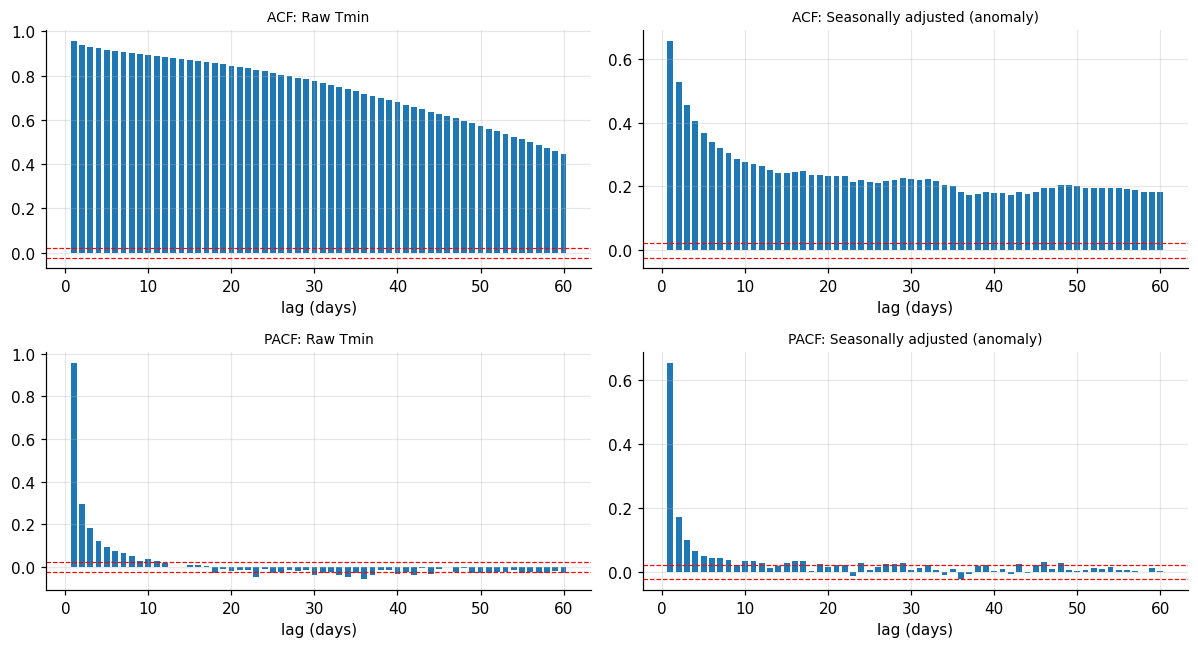

ACF anomaly lag1-10 [0.655 0.528 0.456 0.404 0.366 0.338 0.319 0.304 0.285 0.276]
PACF anomaly lag1-10 [0.655 0.174 0.102 0.066 0.051 0.045 0.044 0.038 0.023 0.036]
significant PACF lags<=30: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 17, 19, 21, 22, 24, 27, 28, 29]
raw ACF lag1/182/365: [ 0.957 -0.807  0.852]
{1: 2.27, 2: 2.44, 3: 2.39, 4: 2.05, 5: 2.32, 6: 1.82, 7: 1.33, 8: 1.56, 9: 1.82, 10: 2.25, 11: 2.16, 12: 1.88}


In [ ]:
# ---------- 3. Chronological split (used for EVERY model) ----------
TR_END,VA_END=pd.Timestamp('2016-12-31'),pd.Timestamp('2021-12-31')
idx=y.index; itr=idx<=TR_END; iva=(idx>TR_END)&(idx<=VA_END); ite=idx>VA_END
RES['split']={'train':[str(idx[itr][0].date()),str(idx[itr][-1].date()),int(itr.sum())],'val':[str(idx[iva][0].date()),str(idx[iva][-1].date()),int(iva.sum())],
              'test':[str(idx[ite][0].date()),str(idx[ite][-1].date()),int(ite.sum())]}
print(RES['split'])
yv=y.values; n=len(yv)
# harmonic seasonal mean fitted on TRAIN only (K chosen by AIC on train)
tt=idx.dayofyear.values/365.25*2*np.pi
def harm(K):
    return np.column_stack([np.ones(n)]+[f(k*tt) for k in range(1,K+1) for f in (np.sin,np.cos)])
aic={}
for K in range(1,7):
    Xh=harm(K); b,_,_,_=np.linalg.lstsq(Xh[itr],yv[itr],rcond=None); r=yv[itr]-Xh[itr]@b; aic[K]=itr.sum()*np.log(np.mean(r**2))+2*(2*K+1)
Kbest=min(aic,key=aic.get); RES['harm_K']=Kbest; RES['harm_aic']={int(k):float(v) for k,v in aic.items()}; print('harmonics K by AIC:',Kbest,{k:round(v) for k,v in aic.items()})
Xh=harm(Kbest); bh,_,_,_=np.linalg.lstsq(Xh[itr],yv[itr],rcond=None); seas_h=Xh@bh
anom=yv-seas_h          # seasonally adjusted series
RES['anom_train_sd']=float(anom[itr].std())
# ACF / PACF of raw and seasonally adjusted series (training data only)
NL=60; fig,ax=plt.subplots(2,2,figsize=(11,6)); cb=1.96/np.sqrt(itr.sum())
for j,(z,nm) in enumerate([(yv[itr],'Raw Tmin'),(anom[itr],'Seasonally adjusted (anomaly)')]):
    for i,(f,t) in enumerate([(acf,'ACF'),(pacf,'PACF')]):
        a=ax[i,j]; vals=f(z,NL); a.bar(range(1,NL+1),vals[1:],width=.7); a.axhline(cb,color='r',ls='--',lw=.8); a.axhline(-cb,color='r',ls='--',lw=.8); a.set_title(f'{t}: {nm}',fontsize=9); a.set_xlabel('lag (days)')
savefig('fig03_acf_pacf')
pa=pacf(anom[itr],30); ac=acf(anom[itr],30); ar_=acf(yv[itr],400)
RES['acf_anom']=[float(v) for v in ac[:11]]; RES['pacf_anom']=[float(v) for v in pa[:11]]
RES['acf_raw_lag1']=float(acf(yv[itr],5)[1]); RES['acf_raw_lag182']=float(ar_[182]); RES['acf_raw_lag365']=float(ar_[365])
RES['sig_pacf_lags']=[int(k) for k in range(1,31) if abs(pa[k])>cb]; RES['sig_acf_count_30']=int(np.sum(np.abs(ac[1:31])>cb)); RES['conf_band']=float(cb)
print('ACF anomaly lag1-10',np.round(ac[1:11],3)); print('PACF anomaly lag1-10',np.round(pa[1:11],3)); print('significant PACF lags<=30:',RES['sig_pacf_lags'])
print('raw ACF lag1/182/365:',np.round([RES['acf_raw_lag1'],RES['acf_raw_lag182'],RES['acf_raw_lag365']],3))
# variance of anomaly by month (seasonal change of spread; matters for interval forecasts)
vm=pd.Series(anom[itr],index=idx[itr]).groupby(idx[itr].month).std(); RES['anom_sd_by_month']={int(k):float(v) for k,v in vm.items()}; print(vm.round(2).to_dict())

In [ ]:
# ---------- metrics ----------
def metrics(yt,yp):
    yt=np.asarray(yt,float); yp=np.asarray(yp,float); e=yt-yp
    rmse=float(np.sqrt(np.mean(e**2))); mae=float(np.mean(np.abs(e)))
    mape=float(100*np.mean(np.abs(e)/(yt+273.15)))          # MAPE in Kelvin: percentage errors in degC are undefined at 0 degC (see report)
    r2=float(1-np.sum(e**2)/np.sum((yt-yt.mean())**2)); return {'RMSE':rmse,'MAE':mae,'MAPE_K':mape,'R2':r2}
PRED={}          # name -> full-length array of one-step-ahead predictions (nan where undefined)
TABLE={}
def register(name,pred):
    pred=np.asarray(pred,float); PRED[name]=pred
    TABLE[name]={s:metrics(yv[m&~np.isnan(pred)],pred[m&~np.isnan(pred)]) for s,m in [('val',iva),('test',ite)]}
    t=TABLE[name]['test']; print(f"{name:34s} test RMSE {t['RMSE']:.3f}  MAE {t['MAE']:.3f}  MAPE(K) {t['MAPE_K']:.3f}%  R2 {t['R2']:.4f}   | val RMSE {TABLE[name]['val']['RMSE']:.3f}")
pers=np.r_[np.nan,yv[:-1]]; register('Persistence (y[t-1])',pers)
register('Climatology (harmonic, train)',seas_h)

Persistence (y[t-1])               test RMSE 1.717  MAE 1.224  MAPE(K) 0.442%  R2 0.9173   | val RMSE 1.906
Climatology (harmonic, train)      test RMSE 2.142  MAE 1.686  MAPE(K) 0.608%  R2 0.8714   | val RMSE 2.147


## Tasks 6-7 - Unit-root tests and making the series stationary
ADF (H0: unit root) and KPSS (H0: stationary) are implemented below. Critical values are the asymptotic MacKinnon values (ADF, constant) and Kwiatkowski et al. (KPSS).

                        series  ADF stat  ADF lags           ADF verdict  KPSS stat               KPSS verdict
                      Raw Tmin    -5.111        25 reject unit root (1%)      0.107 cannot reject stationarity
       First difference of raw   -16.428        25 reject unit root (1%)      0.018 cannot reject stationarity
 Seasonal difference (lag 365)   -11.123        25 reject unit root (1%)      0.218 cannot reject stationarity
Seasonally adjusted (harmonic)   -10.025        23 reject unit root (1%)      1.514   reject stationarity (1%)
Seasonally adjusted + 1st diff   -26.278        25 reject unit root (1%)      0.003 cannot reject stationarity
anomaly, with trend term: ADF -10.22 KPSS 0.909
train anomaly slope per decade -0.405


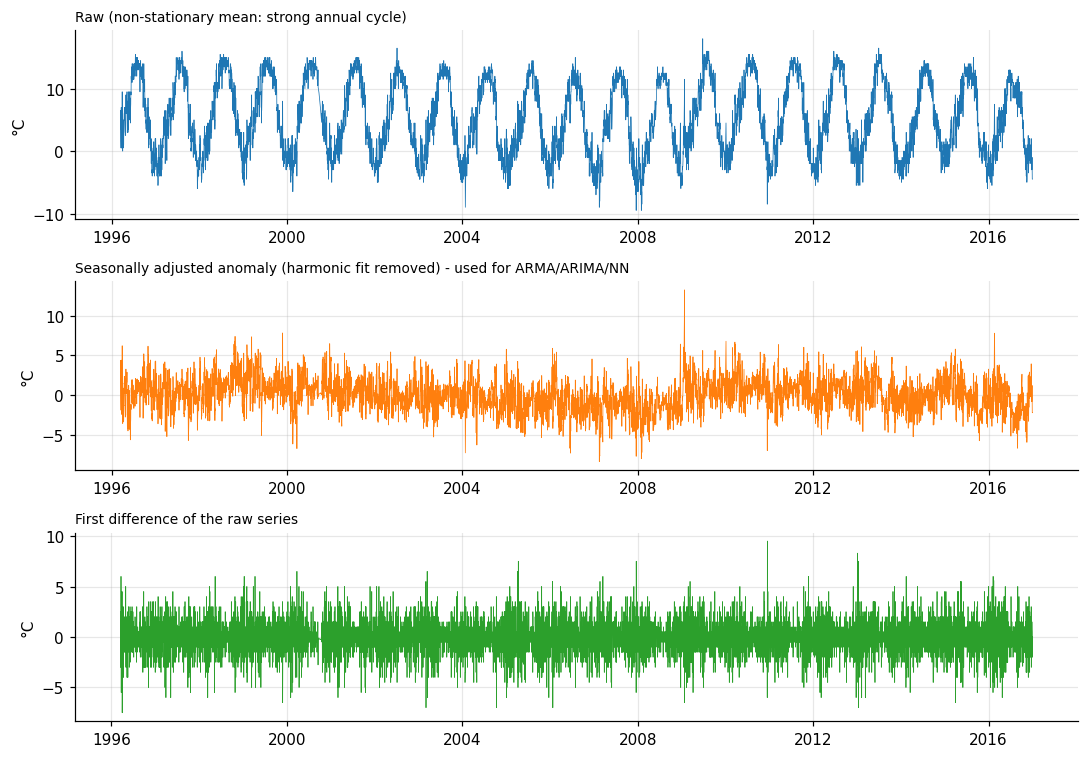

In [ ]:
def ols(X,yy):
    b,_,_,_=np.linalg.lstsq(X,yy,rcond=None); r=yy-X@b; s2=r@r/(len(yy)-X.shape[1]); cov=s2*np.linalg.inv(X.T@X); return b,np.sqrt(np.diag(cov)),r
def adf(z,maxlag=25,reg='c'):
    z=np.asarray(z,float); dz=np.diff(z); best=None
    for L in range(0,maxlag+1):
        Y=dz[L:]; cols=[z[L:-1]]+[dz[L-j:-j] if j<L+1 else None for j in range(1,L+1)]
        cols=[z[L:-1]]+[dz[L-j:len(dz)-j] for j in range(1,L+1)]
        X=np.column_stack(cols+[np.ones(len(Y))]+([np.arange(len(Y))] if reg=='ct' else []))
        b,se,r=ols(X,Y); k=X.shape[1]; aic=len(Y)*np.log(r@r/len(Y))+2*k
        if best is None or aic<best[0]: best=(aic,L,b[0]/se[0],len(Y))
    return {'stat':float(best[2]),'lags':int(best[1]),'nobs':int(best[3])}
ADF_CV={'c':{'1%':-3.4304,'5%':-2.8616,'10%':-2.5668},'ct':{'1%':-3.9598,'5%':-3.4107,'10%':-3.1270}}
def kpss(z,reg='c',nlags=None):
    z=np.asarray(z,float); n=len(z)
    if reg=='c': e=z-z.mean()
    else:
        X=np.column_stack([np.ones(n),np.arange(n)]); e=ols(X,z)[2]
    L=nlags if nlags is not None else int(12*(n/100)**.25); S=np.cumsum(e); s2=e@e/n
    for l in range(1,L+1): s2+=2*(1-l/(L+1))*(e[l:]@e[:-l])/n
    return {'stat':float(np.sum(S**2)/(n**2*s2)),'lags':L}
KPSS_CV={'c':{'10%':0.347,'5%':0.463,'1%':0.739},'ct':{'10%':0.119,'5%':0.146,'1%':0.216}}
def verdict_adf(s,reg): cv=ADF_CV[reg]; return 'reject unit root (1%)' if s<cv['1%'] else 'reject (5%)' if s<cv['5%'] else 'reject (10%)' if s<cv['10%'] else 'cannot reject unit root'
def verdict_kpss(s,reg): cv=KPSS_CV[reg]; return 'reject stationarity (1%)' if s>cv['1%'] else 'reject (5%)' if s>cv['5%'] else 'reject (10%)' if s>cv['10%'] else 'cannot reject stationarity'
cands={'Raw Tmin':yv[itr],'First difference of raw':np.diff(yv[itr]),'Seasonal difference (lag 365)':(yv[365:]-yv[:-365])[itr[365:]],
       'Seasonally adjusted (harmonic)':anom[itr],'Seasonally adjusted + 1st diff':np.diff(anom[itr])}
rows=[]
for nm,z in cands.items():
    a=adf(z); k=kpss(z); rows.append({'series':nm,'ADF stat':a['stat'],'ADF lags':a['lags'],'ADF verdict':verdict_adf(a['stat'],'c'),'KPSS stat':k['stat'],'KPSS verdict':verdict_kpss(k['stat'],'c')})
stat_tab=pd.DataFrame(rows); print(stat_tab.round(3).to_string(index=False)); RES['stationarity']=rows
# trend-stationarity check on the seasonally adjusted series (is there a deterministic trend left?)
k_ct=kpss(anom[itr],'ct'); a_ct=adf(anom[itr],reg='ct'); RES['anom_trend_tests']={'kpss_ct':k_ct,'adf_ct':a_ct}; print('anomaly, with trend term: ADF',round(a_ct['stat'],2),'KPSS',round(k_ct['stat'],3))
sl=stats.theilslopes(anom[itr],np.arange(itr.sum())/365.25); RES['anom_train_slope_per_decade']=float(sl[0]*10); print('train anomaly slope per decade',round(sl[0]*10,3))
fig,ax=plt.subplots(3,1,figsize=(10,7),sharex=False)
ax[0].plot(idx[itr],yv[itr],lw=.5); ax[0].set_title('Raw (non-stationary mean: strong annual cycle)',fontsize=9,loc='left')
ax[1].plot(idx[itr],anom[itr],lw=.5,color='C1'); ax[1].set_title('Seasonally adjusted anomaly (harmonic fit removed) - used for ARMA/ARIMA/NN',fontsize=9,loc='left')
ax[2].plot(idx[itr][1:],np.diff(yv[itr]),lw=.5,color='C2'); ax[2].set_title('First difference of the raw series',fontsize=9,loc='left')
for a in ax: a.set_ylabel('°C')
savefig('fig04_stationarity')

## Tasks 4, 5, 8, 9 - MA, AR, ARIMA, SARIMA (all one-step-ahead)
* Parameters are estimated by conditional least squares **on the training period only**.
* One-step-ahead: the prediction for day *t* uses observations up to day *t-1* (the model is filtered through validation and test with the parameters frozen, never re-fitted).
* `q` is read from the ACF cut-off, `p` from the PACF cut-off, then orders are compared by AIC on the training set and RMSE on the validation set.

In [ ]:
def arma_res(par,z,p,q):
    mu=par[0]; phi=par[1:1+p]; th=par[1+p:1+p+q]
    return signal.lfilter(np.r_[1,-phi],np.r_[1,th],z-mu)
def fit_arma(z,p,q):
    z=np.asarray(z,float)
    if p==0 and q==0: return np.array([z.mean()])
    if q==0:
        X=np.column_stack([np.ones(len(z)-p)]+[z[p-j:len(z)-j] for j in range(1,p+1)]); b=np.linalg.lstsq(X,z[p:],rcond=None)[0]
        phi=b[1:]; mu=b[0]/(1-phi.sum()); return np.r_[mu,phi]
    start=fit_arma(z,max(p,1),0)                              # start from an AR fit
    x0=np.r_[start[0],start[1:1+p] if p>0 else [],np.full(q,0.05)]
    f=lambda par: arma_res(par,z,p,q)[max(p,q):]
    best=None
    for x_init in (x0, np.r_[start[0],np.zeros(p),np.full(q,-0.1)]):
        r=optimize.least_squares(f,x_init,method='trf',diff_step=1e-5,xtol=1e-10,ftol=1e-10,gtol=1e-10,max_nfev=300)
        if best is None or r.cost<best.cost: best=r
    return best.x
def aic_arma(z,par,p,q):
    e=arma_res(par,z,p,q)[max(p,q):]; return len(e)*np.log(np.mean(e**2))+2*(p+q+1)
def onestep(z_full,par,p,q): return z_full-arma_res(par,z_full,p,q)      # z_hat[t] given z[:t]
# transformations: 'none' (raw), 'diff1', 'sdiff365' (seasonal difference), 'harm' (subtract harmonic seasonal mean)
def predict_model(par,p,q,kind):
    if kind=='raw': return onestep(yv,par,p,q)
    if kind=='harm': return seas_h+onestep(anom,par,p,q)
    if kind=='harm_diff1':
        dz=np.r_[0,np.diff(anom)]; return seas_h+np.r_[np.nan,anom[:-1]]+onestep(dz,par,p,q)
    if kind=='diff1':
        dz=np.r_[0,np.diff(yv)]; return np.r_[np.nan,yv[:-1]]+onestep(dz,par,p,q)
    if kind=='sdiff365':
        s=np.full(n,0.); s[365:]=yv[365:]-yv[:-365]; pr=np.full(n,np.nan); zh=onestep(s,par,p,q); pr[365:]=yv[:-365]+zh[365:]; return pr
def series_for(kind):
    if kind=='raw': return yv[itr]
    if kind=='harm': return anom[itr]
    if kind=='diff1': return np.diff(yv[itr])
    if kind=='harm_diff1': return np.diff(anom[itr])
    if kind=='sdiff365': return (yv[365:]-yv[:-365])[itr[365:]]
# --- order tables on the seasonally adjusted series (training data for AIC, validation for RMSE) ---
def order_table(pairs,kind='harm'):
    out=[]; z=series_for(kind)
    for (p,q) in pairs:
        par=fit_arma(z,p,q); pr=predict_model(par,p,q,kind)
        out.append({'p':p,'q':q,'AIC':aic_arma(z,par,p,q),'val_RMSE':float(np.sqrt(np.mean((yv[iva]-pr[iva])**2))),'par':par})
    return pd.DataFrame(out)
t0=time.time()
tab_ar=order_table([(p,0) for p in range(1,13)]); tab_ma=order_table([(0,q) for q in range(1,13)])
tab_arma=order_table([(p,q) for p in range(1,4) for q in range(1,4)])
print('order tables',round(time.time()-t0,1),'s')
for nm,t in [('AR(p)',tab_ar),('MA(q)',tab_ma),('ARMA(p,q)',tab_arma)]:
    print(nm); print(t.drop(columns='par').round(3).to_string(index=False))
RES['order_tables']={nm:t.drop(columns='par').to_dict('records') for nm,t in [('AR',tab_ar),('MA',tab_ma),('ARMA',tab_arma)]}

order tables 2.0 s
AR(p)
 p  q      AIC  val_RMSE
 1  0 6628.833     1.709
 2  0 6397.269     1.675
 3  0 6315.719     1.661
 4  0 6283.876     1.655
 5  0 6264.647     1.652
 6  0 6249.591     1.650
 7  0 6227.282     1.650
 8  0 6216.021     1.648
 9  0 6207.414     1.648
10  0 6199.600     1.644
11  0 6190.433     1.644
12  0 6185.683     1.643
MA(q)
 p  q      AIC  val_RMSE
 0  1 8245.874     1.860
 0  2 7384.339     1.777
 0  3 6981.429     1.736
 0  4 6753.969     1.713
 0  5 6624.628     1.699
 0  6 6541.682     1.684
 0  7 6476.959     1.678
 0  8 6420.278     1.672
 0  9 6387.442     1.673
 0 10 6367.748     1.668
 0 11 6346.805     1.664
 0 12 6320.378     1.662
ARMA(p,q)
 p  q      AIC  val_RMSE
 1  1 6307.966     1.657
 1  2 6246.628     1.647
 1  3 6216.232     1.644
 2  1 6196.002     1.643
 2  2 6130.995     1.633
 2  3 6118.970     1.631
 3  1 6141.495     1.637
 3  2 6117.748     1.631
 3  3 6118.694     1.631


In [ ]:
# ---------- choose fixed p (AR) and q (MA) with a transparent rule ----------
def pick_by_gain(tab,col,thr=0.005):
    v=tab['val_RMSE'].values; k=col
    for i in range(len(v)-1):
        if (v[i]-v[i+1])/v[i]<thr: return int(tab.iloc[i][k])
    return int(tab.iloc[-1][k])
P_AR=pick_by_gain(tab_ar,'p'); Q_MA=pick_by_gain(tab_ma,'q')
best_arma=tab_arma.sort_values('AIC').iloc[0]; P_ARMA,Q_ARMA=int(best_arma.p),int(best_arma.q)
RES['orders']={'p_AR':P_AR,'q_MA':Q_MA,'arma':[P_ARMA,Q_ARMA],'rule':'smallest lag after which one more lag improves validation RMSE by <0.5%'}
print('AR order',P_AR,'| MA order',Q_MA,'| ARMA (AIC) order',(P_ARMA,Q_ARMA))
# ---------- Task 4/5 on the RAW series (as asked), then on the stationary (seasonally adjusted) series ----------
par=fit_arma(yv[itr],0,Q_MA); register(f'MA({Q_MA}) on raw',predict_model(par,0,Q_MA,'raw')); RES['par_MA_raw']=par.tolist()
par=fit_arma(yv[itr],P_AR,0); register(f'AR({P_AR}) on raw',predict_model(par,P_AR,0,'raw')); RES['par_AR_raw']=par.tolist()
par=fit_arma(anom[itr],0,Q_MA); register(f'MA({Q_MA}) on adjusted',predict_model(par,0,Q_MA,'harm')); RES['par_MA_adj']=par.tolist()
par=fit_arma(anom[itr],P_AR,0); register(f'AR({P_AR}) on adjusted',predict_model(par,P_AR,0,'harm')); RES['par_AR_adj']=par.tolist()

AR order 3 | MA order 6 | ARMA (AIC) order (3, 2)
MA(6) on raw                       test RMSE 2.028  MAE 1.555  MAPE(K) 0.560%  R2 0.8847   | val RMSE 2.184
AR(3) on raw                       test RMSE 1.571  MAE 1.152  MAPE(K) 0.415%  R2 0.9308   | val RMSE 1.734
MA(6) on adjusted                  test RMSE 1.557  MAE 1.152  MAPE(K) 0.415%  R2 0.9321   | val RMSE 1.684
AR(3) on adjusted                  test RMSE 1.519  MAE 1.121  MAPE(K) 0.404%  R2 0.9353   | val RMSE 1.661


## Task 8 - ARIMA
The unit-root tests disagree for the seasonally adjusted series (ADF rejects a unit root, KPSS rejects level stationarity), so *d* is decided on validation error:
ARIMA(p,0,q) vs ARIMA(p,1,q) on the adjusted series, and ARIMA(p,1,q) on the raw series.

In [ ]:
t_d1=order_table([(p,q) for p in range(0,4) for q in range(0,4) if (p,q)!=(0,0)],kind='harm_diff1')
t_raw1=order_table([(p,q) for p in range(0,4) for q in range(0,4) if (p,q)!=(0,0)],kind='diff1')
print('ARIMA(p,1,q) on adjusted: best by AIC'); print(t_d1.sort_values('AIC').drop(columns='par').head(3).round(3).to_string(index=False))
print('ARIMA(p,1,q) on raw: best by AIC'); print(t_raw1.sort_values('AIC').drop(columns='par').head(3).round(3).to_string(index=False))
RES['arima_d1_adj_best']=t_d1.sort_values('AIC').drop(columns='par').iloc[0].to_dict(); RES['arima_d1_raw_best']=t_raw1.sort_values('AIC').drop(columns='par').iloc[0].to_dict()
r=t_d1.sort_values('AIC').iloc[0]; pr=predict_model(r.par,int(r.p),int(r.q),'harm_diff1'); register(f'ARIMA({int(r.p)},1,{int(r.q)}) on adjusted',pr)
r=t_raw1.sort_values('AIC').iloc[0]; pr=predict_model(r.par,int(r.p),int(r.q),'diff1'); register(f'ARIMA({int(r.p)},1,{int(r.q)}) on raw',pr)
par=best_arma.par; ARIMA_NAME=f'ARIMA({P_ARMA},0,{Q_ARMA}) on adjusted'; register(ARIMA_NAME,predict_model(par,P_ARMA,Q_ARMA,'harm')); RES['par_ARIMA']=par.tolist()
roots_ar=np.abs(np.roots(np.r_[1,-par[1:1+P_ARMA]])); roots_ma=np.abs(np.roots(np.r_[1,par[1+P_ARMA:]]))
RES['arima_roots']={'ar_min_abs_root_inv':float(np.max(1/np.abs(np.roots(np.r_[1,-par[1:1+P_ARMA]][::-1])))) if False else float(np.max(np.abs(np.roots(np.r_[1,-par[1:1+P_ARMA]])))),'ma_max_abs_root':float(np.max(np.abs(np.roots(np.r_[1,par[1+P_ARMA:]]))))}
# residual diagnostics on training
e=arma_res(par,anom[itr],P_ARMA,Q_ARMA)[max(P_ARMA,Q_ARMA):]; Q,pv=ljungbox(e,20); RES['arima_lb']={'Q20':float(Q),'p':float(pv)}; print('ARIMA residual Ljung-Box(20): Q=%.1f p=%.3g'%(Q,pv))
RES['arima_resid_sd_by_month']={int(k):float(v) for k,v in pd.Series(e,index=idx[itr][max(P_ARMA,Q_ARMA):]).groupby(idx[itr][max(P_ARMA,Q_ARMA):].month).std().items()}

ARIMA(p,1,q) on adjusted: best by AIC
 p  q      AIC  val_RMSE
 2  3 6129.016     1.631
 3  2 6131.100     1.632
 2  2 6132.178     1.632
ARIMA(p,1,q) on raw: best by AIC
 p  q      AIC  val_RMSE
 3  3 6586.591     1.686
 1  2 6690.321     1.696
 2  1 6690.425     1.696
ARIMA(2,1,3) on adjusted           test RMSE 1.510  MAE 1.123  MAPE(K) 0.405%  R2 0.9361   | val RMSE 1.631
ARIMA(3,1,3) on raw                test RMSE 1.553  MAE 1.152  MAPE(K) 0.415%  R2 0.9324   | val RMSE 1.686
ARIMA(3,0,2) on adjusted           test RMSE 1.507  MAE 1.119  MAPE(K) 0.403%  R2 0.9363   | val RMSE 1.631
ARIMA residual Ljung-Box(20): Q=9.8 p=0.971


## Task 9 - SARIMA (annual season, s = 365)
True seasonal differencing at lag 365 followed by an ARMA on the differenced series, i.e. SARIMA(p,0,q)(0,1,0)[365]. The alternative used above (harmonic regression + ARMA errors) is the usual way to handle a 365-day season.

In [ ]:
t_s=order_table([(p,q) for p in range(0,4) for q in range(0,4) if (p,q)!=(0,0)],kind='sdiff365')
print(t_s.sort_values('AIC').drop(columns='par').head(4).round(3).to_string(index=False))
r=t_s.sort_values('AIC').iloc[0]; SAR_NAME=f'SARIMA({int(r.p)},0,{int(r.q)})(0,1,0)[365]'
register(SAR_NAME,predict_model(r.par,int(r.p),int(r.q),'sdiff365')); RES['sarima_order']=[int(r.p),int(r.q)]

 p  q       AIC  val_RMSE
 3  2 10734.940     2.292
 2  3 10737.190     2.292
 2  2 10741.222     2.291
 3  3 10742.454     2.291
SARIMA(3,0,2)(0,1,0)[365]          test RMSE 2.217  MAE 1.671  MAPE(K) 0.603%  R2 0.8622   | val RMSE 2.292


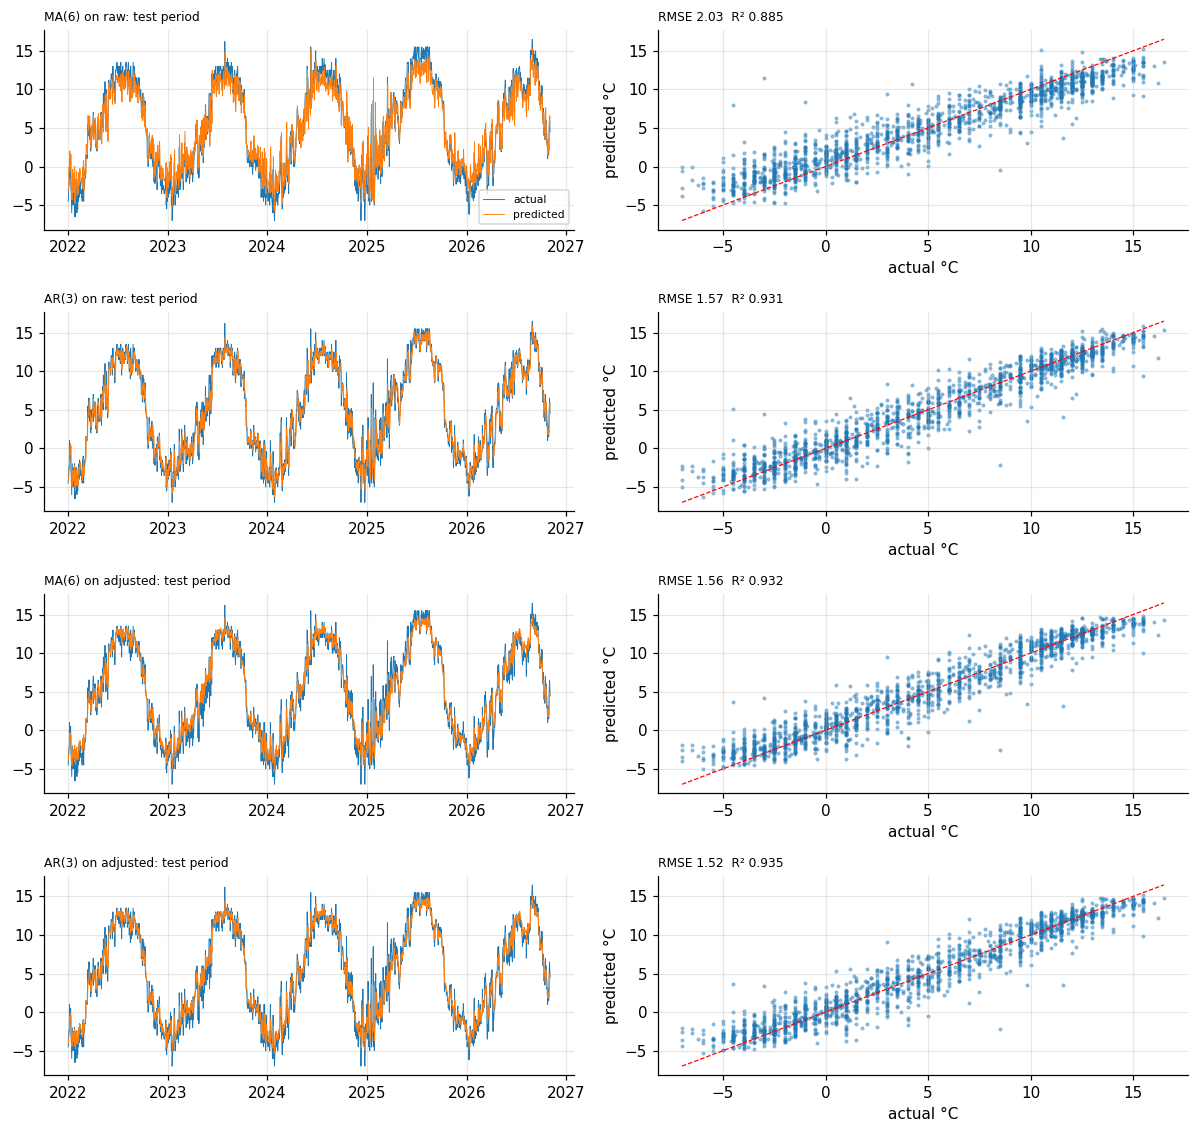

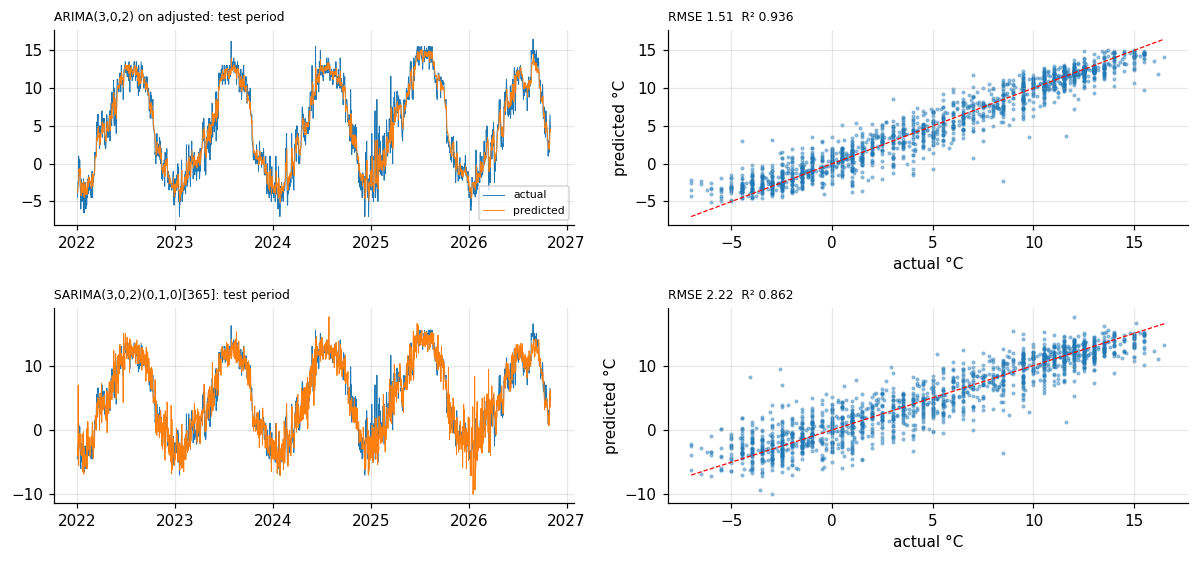

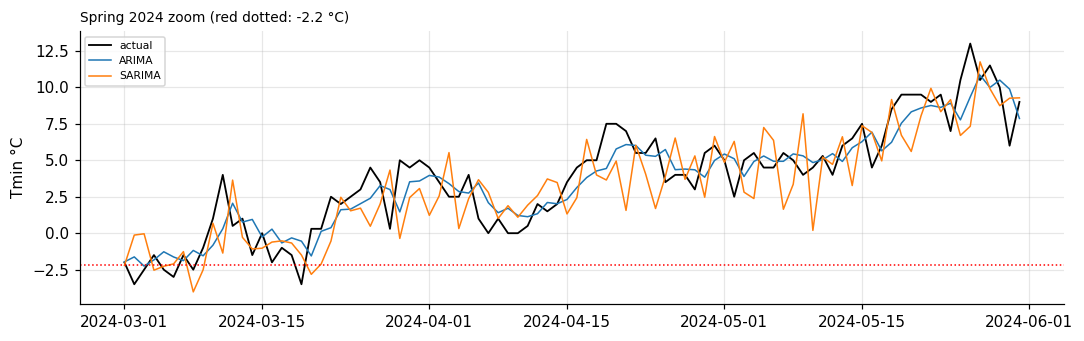

In [ ]:
# ---------- plots: predicted vs actual for each classical model ----------
def pred_plots(names,fname,rng=('2024-03-01','2024-06-30')):
    fig,ax=plt.subplots(len(names),2,figsize=(11,2.6*len(names)))
    for i,nm in enumerate(names):
        pr=PRED[nm]; m=ite&~np.isnan(pr)
        a=ax[i,0]; a.plot(idx[m],yv[m],lw=.6,label='actual'); a.plot(idx[m],pr[m],lw=.6,label='predicted'); a.set_title(f'{nm}: test period',fontsize=8,loc='left')
        a=ax[i,1]; a.scatter(yv[m],pr[m],s=3,alpha=.4); lo,hi=yv[m].min(),yv[m].max(); a.plot([lo,hi],[lo,hi],'r--',lw=.8); a.set_xlabel('actual °C'); a.set_ylabel('predicted °C')
        a.set_title(f"RMSE {TABLE[nm]['test']['RMSE']:.2f}  R² {TABLE[nm]['test']['R2']:.3f}",fontsize=8,loc='left')
        if i==0: ax[i,0].legend(fontsize=7)
    savefig(fname)
pred_plots([f'MA({Q_MA}) on raw',f'AR({P_AR}) on raw',f'MA({Q_MA}) on adjusted',f'AR({P_AR}) on adjusted'],'fig05_ma_ar')
pred_plots([ARIMA_NAME,SAR_NAME],'fig06_arima_sarima')
# zoom for readability: spring 2024
fig,ax=plt.subplots(figsize=(10,3.2)); m=(idx>='2024-03-01')&(idx<='2024-05-31')
ax.plot(idx[m],yv[m],'k',lw=1.2,label='actual'); ax.plot(idx[m],PRED[ARIMA_NAME][m],lw=1,label='ARIMA'); ax.plot(idx[m],PRED[SAR_NAME][m],lw=1,label='SARIMA')
ax.axhline(-2.2,color='r',ls=':',lw=1); ax.set_ylabel('Tmin °C'); ax.legend(fontsize=7); ax.set_title('Spring 2024 zoom (red dotted: -2.2 °C)',fontsize=9,loc='left'); savefig('fig07_spring_zoom')

## Tasks 10-11 - RNN and LSTM (NumPy implementation with back-propagation through time)
* Input window: last `lag` seasonally adjusted temperatures (standardised with training mean/sd) plus sin/cos of the day-of-year of the *following* day (known in advance).
* Output: next day's adjusted temperature; the harmonic seasonal mean is added back so metrics are in °C and comparable with all other models.
* Same chronological split. Training uses the training set only; early stopping and hyper-parameter selection use the validation set; the test set is touched once at the end.
* Adam optimiser, gradient-norm clipping at 1.0, random search over lag, batch size, learning rate, layers and neurons.

In [ ]:
sig=lambda a:1/(1+np.exp(-a))
class Recurrent:
    def __init__(s,kind,nin,nh,rng):
        s.kind=kind; s.nin=nin; s.nh=nh; G=4*nh if kind=='lstm' else nh
        s.W=rng.normal(0,1/np.sqrt(nin+nh),(nin+nh,G)); s.b=np.zeros(G)
        if kind=='lstm': s.b[nh:2*nh]=1.0         # forget-gate bias
        s.params=[s.W,s.b]
    def forward(s,X):
        B,T,_=X.shape; H=s.nh; h=np.zeros((B,H)); c=np.zeros((B,H)); out=np.empty((B,T,H)); s.cache=[]
        for t in range(T):
            zin=np.concatenate([X[:,t],h],1); z=zin@s.W+s.b
            if s.kind=='lstm':
                i=sig(z[:,:H]); f=sig(z[:,H:2*H]); g=np.tanh(z[:,2*H:3*H]); o=sig(z[:,3*H:]); cn=f*c+i*g; tc=np.tanh(cn); hn=o*tc
                s.cache.append((zin,i,f,g,o,c,tc)); c=cn
            else:
                hn=np.tanh(z); s.cache.append((zin,hn))
            h=hn; out[:,t]=h
        return out
    def backward(s,dout):
        B,T,_=dout.shape; H=s.nh; dW=np.zeros_like(s.W); db=np.zeros_like(s.b); dX=np.empty((B,T,s.nin)); dh_n=np.zeros((B,H)); dc_n=np.zeros((B,H))
        for t in reversed(range(T)):
            dh=dout[:,t]+dh_n
            if s.kind=='lstm':
                zin,i,f,g,o,cp,tc=s.cache[t]; do=dh*tc; dc=dh*o*(1-tc**2)+dc_n; di=dc*g; dg=dc*i; df=dc*cp; dc_n=dc*f
                dz=np.concatenate([di*i*(1-i),df*f*(1-f),dg*(1-g**2),do*o*(1-o)],1)
            else:
                zin,hn=s.cache[t]; dz=dh*(1-hn**2)
            dW+=zin.T@dz; db+=dz.sum(0); dzin=dz@s.W.T; dX[:,t]=dzin[:,:s.nin]; dh_n=dzin[:,s.nin:]
        return dX,[dW,db]
class Net:
    def __init__(s,kind,nin,nh,layers,seed):
        rng=np.random.default_rng(seed); s.layers=[Recurrent(kind,nin if l==0 else nh,nh,rng) for l in range(layers)]
        s.Wo=rng.normal(0,1/np.sqrt(nh),(nh,1)); s.bo=np.zeros(1); s.params=[p for l in s.layers for p in l.params]+[s.Wo,s.bo]
    def forward(s,X):
        a=X
        for l in s.layers: a=l.forward(a)
        s.hlast=a[:,-1]; s.aout=a; return (s.hlast@s.Wo+s.bo)[:,0]
    def backward(s,dy):
        grads=[]; dh=np.zeros_like(s.aout); dh[:,-1]=(dy[:,None]@s.Wo.T)
        dWo=s.hlast.T@dy[:,None]; dbo=np.array([dy.sum()]); lg=[]
        for l in reversed(s.layers): dh,g=l.backward(dh); lg=g+lg
        return lg+[dWo,dbo]
    def get(s): return [p.copy() for p in s.params]
    def set(s,w):
        for p,v in zip(s.params,w): p[...]=v
class Adam:
    def __init__(s,params,lr): s.p=params; s.lr=lr; s.m=[np.zeros_like(p) for p in params]; s.v=[np.zeros_like(p) for p in params]; s.t=0
    def step(s,grads,clip=1.0):
        gn=np.sqrt(sum(np.sum(g*g) for g in grads)); sc=min(1.0,clip/(gn+1e-12)); s.t+=1
        for p,g,m,v in zip(s.p,grads,s.m,s.v):
            g=g*sc; m[...]=.9*m+.1*g; v[...]=.999*v+.001*g*g; p-=s.lr*(m/(1-.9**s.t))/(np.sqrt(v/(1-.999**s.t))+1e-8)
def loss_grad(pred,yt,tau=None):
    u=yt-pred
    if tau is None: return np.mean(u**2),(-2*u/len(u))
    return np.mean(np.maximum(tau*u,(tau-1)*u)),(np.where(u>0,-tau,1-tau)/len(u))
# ---- data windows ----
SD=anom[itr].std(); az=anom/SD
nxt=idx.append(pd.DatetimeIndex([idx[-1]+pd.Timedelta(days=1)]))[1:]; ph=nxt.dayofyear.values/365.25*2*np.pi; seasf=np.column_stack([np.sin(ph),np.cos(ph)])
FEAT=np.column_stack([az,seasf])          # row t = [anomaly of day t, calendar of day t+1]
def windows(lag,targets):
    """targets: integer positions t>=lag; input = FEAT[t-lag:t]; label = az[t]"""
    ii=targets[:,None]-lag+np.arange(lag)[None,:]; return FEAT[ii],az[targets]
def make_sets(lag):
    pos=np.arange(n); pos=pos[pos>=lag]
    return {nm:pos[m[pos]] for nm,m in [('tr',itr),('va',iva),('te',ite)]}
def fit_net(kind,lag,nh,layers,lr,bs,seed=0,epochs=40,patience=6,tau=None,verbose=False):
    S=make_sets(lag); Xtr,ytr=windows(lag,S['tr']); Xva,yva=windows(lag,S['va'])
    net=Net(kind,3,nh,layers,seed); opt=Adam(net.params,lr); rng=np.random.default_rng(seed+1); best=(1e9,None,0); hist=[]
    for ep in range(epochs):
        perm=rng.permutation(len(Xtr)); tl=0
        for k in range(0,len(perm),bs):
            b=perm[k:k+bs]; p=net.forward(Xtr[b]); l,dy=loss_grad(p,ytr[b],tau); opt.step(net.backward(dy)); tl+=l*len(b)
        pv=net.forward(Xva); lv=loss_grad(pv,yva,tau)[0]; hist.append((tl/len(perm),lv))
        if lv<best[0]-1e-5: best=(lv,net.get(),ep)
        elif ep-best[2]>=patience: break
    net.set(best[1]); return net,best[0],best[2],hist
def net_predict(net,lag,tau=None):
    S=make_sets(lag); out=np.full(n,np.nan)
    allpos=np.concatenate([S['tr'],S['va'],S['te']]); X,_=windows(lag,allpos); out[allpos]=net.forward(X)*SD+seas_h[allpos]
    return out
# calendar feature alignment check: FEAT row t-1 must carry the calendar of day t
assert np.allclose(FEAT[10,1:],[np.sin(idx[11].dayofyear/365.25*2*np.pi),np.cos(idx[11].dayofyear/365.25*2*np.pi)])

rnn {'lag': 30, 'nh': 16, 'layers': 2, 'lr': 0.001, 'bs': 128, 'best_epoch': 7, 'val_RMSE': 1.6394707667360753, 'sec': 5.8}
rnn {'lag': 30, 'nh': 32, 'layers': 1, 'lr': 0.01, 'bs': 64, 'best_epoch': 10, 'val_RMSE': 1.6604481107185132, 'sec': 8.0}
rnn {'lag': 7, 'nh': 32, 'layers': 2, 'lr': 0.01, 'bs': 128, 'best_epoch': 3, 'val_RMSE': 1.655900306027098, 'sec': 2.3}
rnn {'lag': 30, 'nh': 8, 'layers': 2, 'lr': 0.01, 'bs': 128, 'best_epoch': 4, 'val_RMSE': 1.6349325165095803, 'sec': 2.4}
rnn {'lag': 30, 'nh': 8, 'layers': 1, 'lr': 0.01, 'bs': 256, 'best_epoch': 14, 'val_RMSE': 1.6334412905757647, 'sec': 2.5}
rnn {'lag': 7, 'nh': 32, 'layers': 1, 'lr': 0.003, 'bs': 128, 'best_epoch': 7, 'val_RMSE': 1.6471634368923511, 'sec': 1.7}
rnn {'lag': 14, 'nh': 16, 'layers': 2, 'lr': 0.001, 'bs': 256, 'best_epoch': 5, 'val_RMSE': 1.6443965762668444, 'sec': 2.1}
rnn {'lag': 30, 'nh': 32, 'layers': 2, 'lr': 0.003, 'bs': 256, 'best_epoch': 4, 'val_RMSE': 1.644388676443066, 'sec': 9.9}
rnn {'lag': 14, '

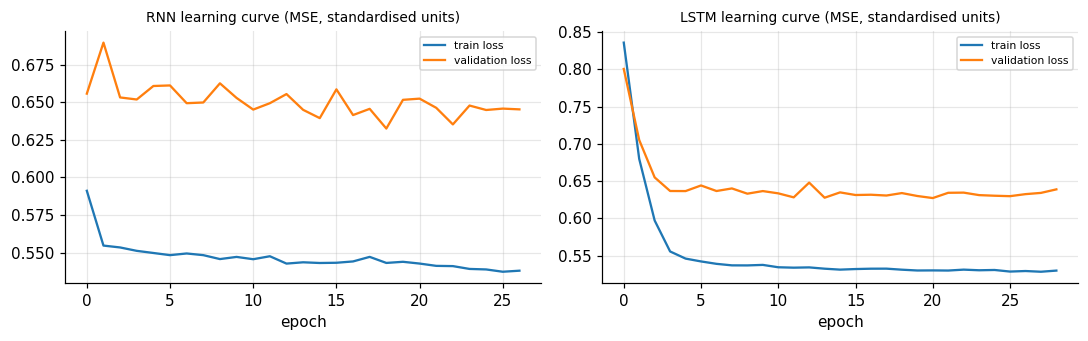

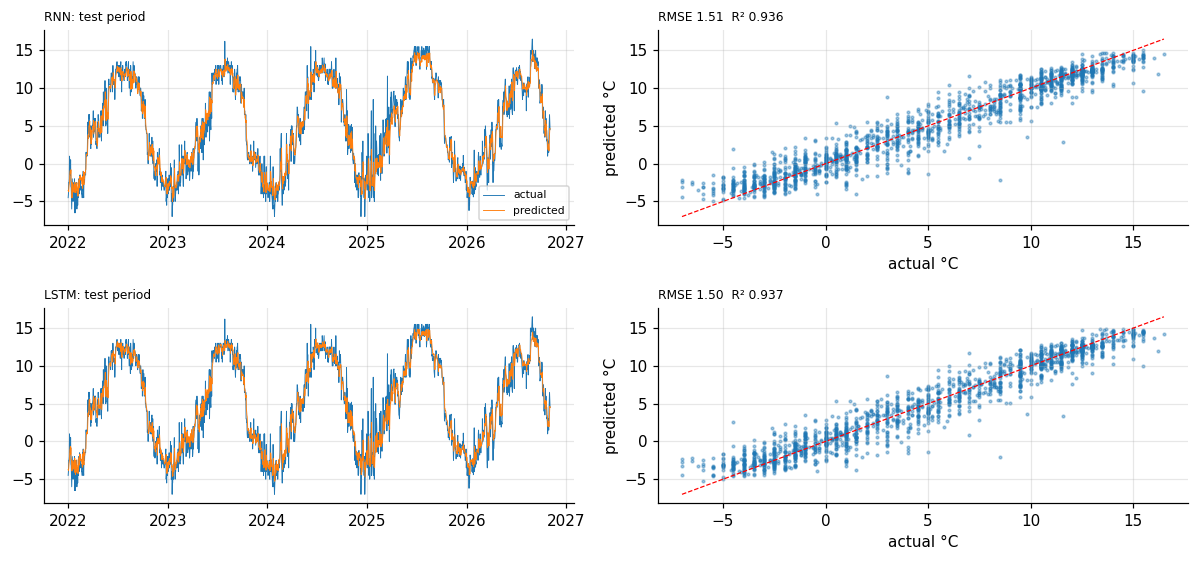

In [ ]:
# ---------- hyper-parameter random search on the VALIDATION set ----------
N_TRIALS=16
space={'lag':[7,14,30],'nh':[8,16,32],'layers':[1,2],'lr':[1e-2,3e-3,1e-3],'bs':[64,128,256]}
def search(kind,seed=7):
    rng=np.random.default_rng(seed); rows=[]; seen=set()
    while len(rows)<N_TRIALS:
        cfg={k:v[rng.integers(len(v))] for k,v in space.items()}; key=tuple(cfg.values())
        if key in seen: continue
        seen.add(key); t0=time.time()
        net,lv,be,h=fit_net(kind,cfg['lag'],cfg['nh'],cfg['layers'],cfg['lr'],cfg['bs'],seed=0,epochs=40,patience=5)
        pr=net_predict(net,cfg['lag']); rm=float(np.sqrt(np.mean((yv[iva]-pr[iva])**2)))
        rows.append({**cfg,'best_epoch':be+1,'val_RMSE':rm,'sec':round(time.time()-t0,1)}); print(kind,rows[-1],flush=True)
    return pd.DataFrame(rows).sort_values('val_RMSE').reset_index(drop=True)
TUNE={}; NETS={}
for kind in ['rnn','lstm']:
    TUNE[kind]=search(kind); b=TUNE[kind].iloc[0]; cfg={k:(int(b[k]) if k!='lr' else float(b[k])) for k in space}
    net,lv,be,h=fit_net(kind,cfg['lag'],cfg['nh'],cfg['layers'],cfg['lr'],cfg['bs'],seed=0,epochs=60,patience=8)
    NETS[kind]=(net,cfg,h); register(kind.upper(),net_predict(net,cfg['lag']))
    RES[f'{kind}_best_cfg']=cfg; RES[f'{kind}_tuning']=TUNE[kind].to_dict('records'); RES[f'{kind}_epochs']=len(h)
    print(kind.upper(),'best config',cfg,'epochs run',len(h))
fig,ax=plt.subplots(1,2,figsize=(10,3.2))
for a,kind in zip(ax,['rnn','lstm']):
    h=np.array(NETS[kind][2]); a.plot(h[:,0],label='train loss'); a.plot(h[:,1],label='validation loss'); a.set_title(kind.upper()+' learning curve (MSE, standardised units)',fontsize=9); a.set_xlabel('epoch'); a.legend(fontsize=7)
savefig('fig08_learning_curves')
pred_plots(['RNN','LSTM'],'fig09_rnn_lstm')

## Task 13 - Probabilistic forecast: a pair of LSTMs trained with the pinball loss
One LSTM estimates the 2.5 % quantile and one the 97.5 % quantile (same architecture as the tuned LSTM). Together they give a 95 % prediction interval.
PICP = share of test values inside the interval; MPIW = mean interval width.
Because quantile networks are often slightly mis-calibrated, a split-conformal correction (CQR, Romano et al. 2019) estimated on the validation set is also reported.

tau 0.025 epochs 37 best val pinball 0.0462
tau 0.975 epochs 29 best val pinball 0.0513
raw   {'val': {'PICP': 0.9468784227820373, 'MPIW': 6.133798127670094}, 'test': {'PICP': 0.955291454442558, 'MPIW': 6.022607916886156}}
CQR   {'val': {'PICP': 0.9507119386637459, 'MPIW': 6.2310567312930685}, 'test': {'PICP': 0.9581211092246746, 'MPIW': 6.119866520509131}} shift 0.049
ARIMA +/-1.96 sd {'val': {'PICP': 0.9244249726177437, 'MPIW': 5.8612059153609914}, 'test': {'PICP': 0.9456706281833617, 'MPIW': 5.861205915360991}}


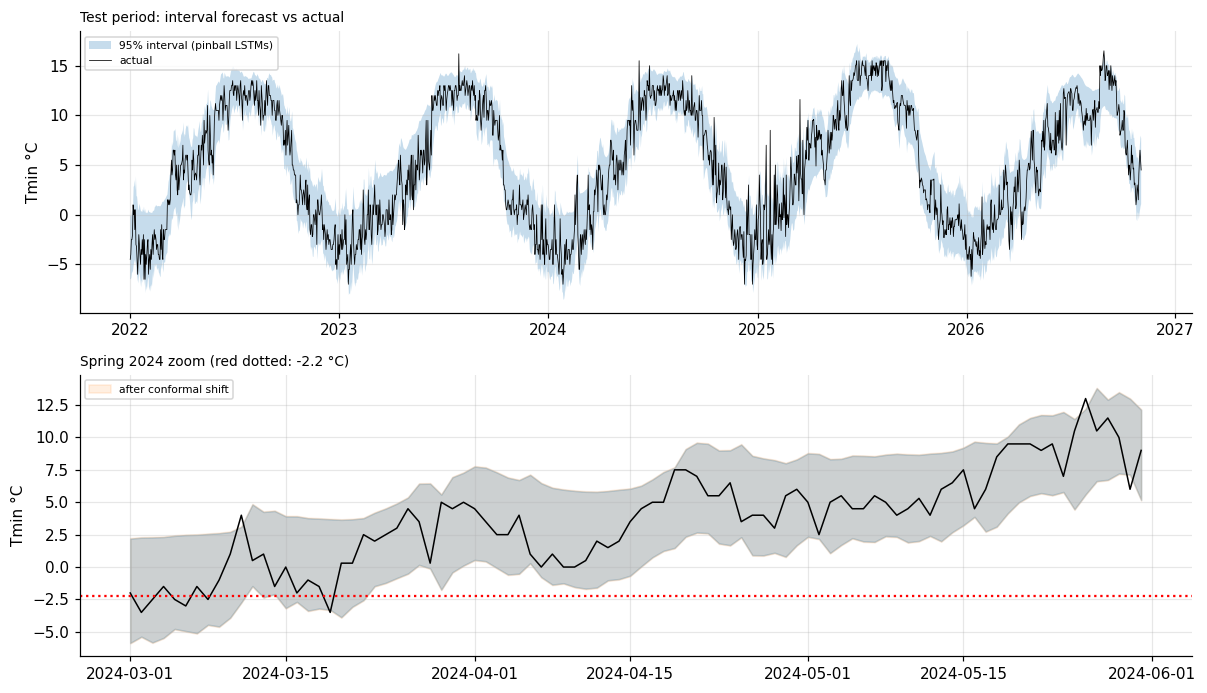

In [ ]:
cfg=NETS['lstm'][1]; QN={}
for tau in (0.025,0.975):
    net,lv,be,h=fit_net('lstm',cfg['lag'],cfg['nh'],cfg['layers'],cfg['lr'],cfg['bs'],seed=3,epochs=80,patience=10,tau=tau); QN[tau]=net
    print('tau',tau,'epochs',len(h),'best val pinball',round(lv,4))
qlo=net_predict(QN[0.025],cfg['lag']); qhi=net_predict(QN[0.975],cfg['lag'])
RES['quantile_crossing_test']=int(np.sum(qlo[ite]>qhi[ite]))
lo=np.minimum(qlo,qhi); hi=np.maximum(qlo,qhi)
def picp_mpiw(lo_,hi_,m):
    ins=(yv[m]>=lo_[m])&(yv[m]<=hi_[m]); return float(ins.mean()),float(np.mean(hi_[m]-lo_[m]))
RES['interval_raw']={s:dict(zip(['PICP','MPIW'],picp_mpiw(lo,hi,m))) for s,m in [('val',iva),('test',ite)]}
# split-conformal (CQR) on validation
sc=np.maximum(lo[iva]-yv[iva],yv[iva]-hi[iva]); nv=len(sc); Qc=float(np.quantile(sc,min(1,np.ceil((nv+1)*.95)/nv)))
lo_c,hi_c=lo-Qc,hi+Qc; RES['cqr_shift']=Qc; RES['interval_cqr']={s:dict(zip(['PICP','MPIW'],picp_mpiw(lo_c,hi_c,m))) for s,m in [('val',iva),('test',ite)]}
print('raw  ',RES['interval_raw']); print('CQR  ',RES['interval_cqr'],'shift',round(Qc,3))
# Gaussian benchmark: ARIMA point forecast +/- 1.96 * training residual sd  (what a text-book interval would give)
sd_tr=np.sqrt(np.mean((yv[itr]-PRED[ARIMA_NAME][itr])**2)); glo,ghi=PRED[ARIMA_NAME]-1.96*sd_tr,PRED[ARIMA_NAME]+1.96*sd_tr
RES['interval_gauss']={s:dict(zip(['PICP','MPIW'],picp_mpiw(glo,ghi,m))) for s,m in [('val',iva),('test',ite)]}; print('ARIMA +/-1.96 sd',RES['interval_gauss'])
# coverage by month (test) and in the spring window
mo=idx.month.values; RES['picp_by_month_test']={int(k):float(((yv>=lo)&(yv<=hi))[ite&(mo==k)].mean()) for k in range(1,13) if (ite&(mo==k)).any()}
RES['mpiw_by_month_test']={int(k):float((hi-lo)[ite&(mo==k)].mean()) for k in range(1,13) if (ite&(mo==k)).any()}
# Wilson 95% CI for test PICP (treats days as independent; optimistic because of autocorrelation)
pc=RES['interval_raw']['test']['PICP']; nt=int(ite.sum()); z=1.96; ctr=(pc+z*z/2/nt)/(1+z*z/nt); hw=z*np.sqrt(pc*(1-pc)/nt+z*z/4/nt**2)/(1+z*z/nt); RES['picp_test_wilson']=[float(ctr-hw),float(ctr+hw)]
fig,ax=plt.subplots(2,1,figsize=(11,6.4))
m=ite; ax[0].fill_between(idx[m],lo[m],hi[m],alpha=.25,label='95% interval (pinball LSTMs)'); ax[0].plot(idx[m],yv[m],'k',lw=.5,label='actual'); ax[0].legend(fontsize=7,loc='upper left'); ax[0].set_ylabel('Tmin °C'); ax[0].set_title('Test period: interval forecast vs actual',fontsize=9,loc='left')
m=(idx>='2024-03-01')&(idx<='2024-05-31'); ax[1].fill_between(idx[m],lo[m],hi[m],alpha=.25,color='C0'); ax[1].fill_between(idx[m],lo_c[m],hi_c[m],alpha=.12,color='C1',label='after conformal shift'); ax[1].plot(idx[m],yv[m],'k',lw=1); ax[1].axhline(-2.2,color='r',ls=':'); ax[1].legend(fontsize=7); ax[1].set_ylabel('Tmin °C'); ax[1].set_title('Spring 2024 zoom (red dotted: -2.2 °C)',fontsize=9,loc='left')
savefig('fig10_interval')
PRED['QLO']=lo; PRED['QHI']=hi; PRED['QLO_c']=lo_c; PRED['QHI_c']=hi_c

## Tasks 12 and 14 - From forecasts to a frost-protection decision, and risk
**Decision.** Each evening in the bloom-sensitive window (15 March - 15 May) the orchard manager decides whether to run frost protection
(smudge fires / heaters / sprinklers / covers) for the coming night. The forecast of tomorrow's minimum temperature drives that choice.

**Cost-loss model.** Protecting costs C for the night. If the night is damaging (Tmin <= threshold) and the orchard was *not* protected, the loss is L.
Only the ratio c = C/L matters, so results are in **units of L** (no money figures are invented). Protection is assumed fully effective when applied.

**Thresholds.** -2.2 °C (28 °F) is the 10 %-bud-kill temperature from first pink to post-bloom for apple (WSU EB0913, compiled by Michigan State Univ. Extension).
The same sources warn that actual critical temperatures shift by 4-5 °F with recent weather, and a screen-height thermometer reads warmer than the blossom canopy on radiation-frost nights,
so a precautionary 0 °C alert level is analysed as well.

**Rules compared** (the margin *m* of each forecast rule is tuned on the validation years only):
never protect; always protect; perfect foresight (lower bound); persistence; seasonal climatology; ARIMA; LSTM; and the interval rule "protect if the lower bound of the 95 % interval is below the threshold".

### Are the models' accuracies really different? Diebold-Mariano test (squared-error loss, Newey-West variance, test period)

In [ ]:
def dm_test(e1,e2,lag=5):
    ok_=~(np.isnan(e1)|np.isnan(e2)); d=(e1**2-e2**2)[ok_]; n_=len(d); dbar=d.mean()
    g=[np.mean((d[k:]-dbar)*(d[:n_-k]-dbar)) for k in range(lag+1)]; var=(g[0]+2*sum((1-k/(lag+1))*g[k] for k in range(1,lag+1)))/n_
    s_=dbar/np.sqrt(var); return float(dbar),float(s_),float(2*(1-stats.norm.cdf(abs(s_))))
err=lambda nm:(yv-PRED[nm])[ite]
DM={}
for a_,b_ in [('LSTM',ARIMA_NAME),('RNN',ARIMA_NAME),('LSTM','RNN'),(ARIMA_NAME,'Persistence (y[t-1])'),(ARIMA_NAME,f'AR({P_AR}) on adjusted'),(ARIMA_NAME,'Climatology (harmonic, train)'),('LSTM','Persistence (y[t-1])')]:
    dbar,st_,pv_=dm_test(err(a_),err(b_)); DM[f'{a_} vs {b_}']={'mean_sq_err_diff':dbar,'DM':st_,'p':pv_}; print(f'{a_:>28s} vs {b_:<32s} mean(e1^2-e2^2)={dbar:+.3f}  DM={st_:+.2f}  p={pv_:.3f}')
RES['dm']=DM

                        LSTM vs ARIMA(3,0,2) on adjusted         mean(e1^2-e2^2)=-0.020  DM=-0.74  p=0.459
                         RNN vs ARIMA(3,0,2) on adjusted         mean(e1^2-e2^2)=+0.017  DM=+0.57  p=0.571
                        LSTM vs RNN                              mean(e1^2-e2^2)=-0.037  DM=-1.70  p=0.089
    ARIMA(3,0,2) on adjusted vs Persistence (y[t-1])             mean(e1^2-e2^2)=-0.678  DM=-7.07  p=0.000
    ARIMA(3,0,2) on adjusted vs AR(3) on adjusted                mean(e1^2-e2^2)=-0.036  DM=-1.76  p=0.079
    ARIMA(3,0,2) on adjusted vs Climatology (harmonic, train)    mean(e1^2-e2^2)=-2.315  DM=-10.89  p=0.000
                        LSTM vs Persistence (y[t-1])             mean(e1^2-e2^2)=-0.698  DM=-6.26  p=0.000


threshold -2.2 test nights 310 events 6 | val events 3
                               0.02   0.05   0.1   0.2
never                          6.00   6.00   6.0   6.0
always                         6.20  15.50  31.0  62.0
perfect                        0.12   0.30   0.6   1.2
Persistence                    4.28   4.70   5.4   6.8
Climatology                    4.48   5.20   5.4   6.0
ARIMA                          4.30   4.75   5.5   6.0
LSTM                           5.18   5.45   5.9   7.0
Interval-95 (raw)              1.80   3.00   5.0   9.0
Interval-95 (conformal)        1.86   3.15   5.3   9.6
Interval lower bound, tuned m  3.30   3.75   4.5   6.4
threshold 0.0 test nights 310 events 39 | val events 32
                                0.02   0.05   0.1   0.2
never                          39.00  39.00  39.0  39.0
always                          6.20  15.50  31.0  62.0
perfect                         0.78   1.95   3.9   7.8
Persistence                     4.08   7.40  11.3  25.2
Clim

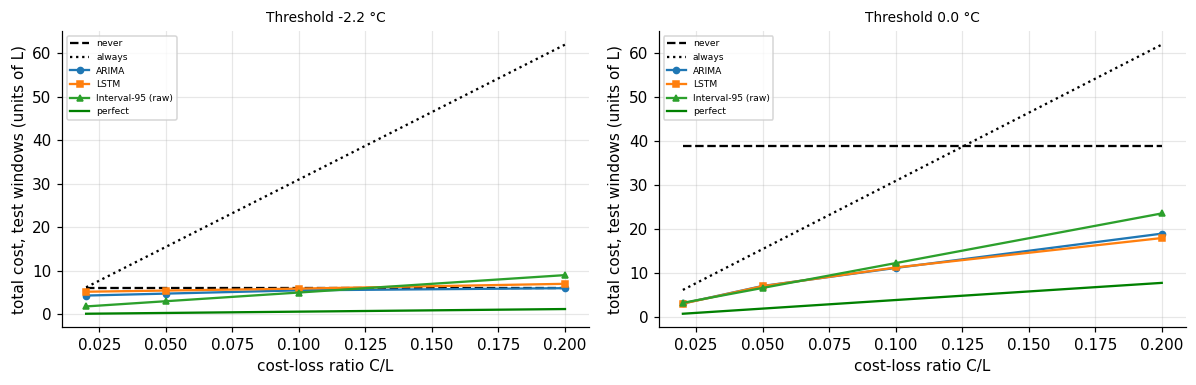

In [ ]:
dayv=idx.day.values; mo=idx.month.values
inwin=((mo==3)&(dayv>=15))|(mo==4)|((mo==5)&(dayv<=15))
THETAS={'-2.2':-2.2,'0.0':0.0}; CRATIOS=[0.02,0.05,0.10,0.20]
def rule_cost(protect,event,c): return c*protect.sum()+np.sum(event&~protect)
def tune_margin(fc,theta,c,mask,grid=np.arange(-2,6.01,0.1)):
    ev=yv<=theta; best=None
    for m in grid:
        pr=fc<=theta+m; k=rule_cost(pr[mask],ev[mask],c)
        if best is None or k<best[0]-1e-9: best=(k,m)
    return best[1]
fc_models={'Persistence':PRED['Persistence (y[t-1])'],'Climatology':PRED['Climatology (harmonic, train)'],'ARIMA':PRED[ARIMA_NAME],'LSTM':PRED['LSTM']}
vm=iva&inwin; tm=ite&inwin
DEC={}
for tk,theta in THETAS.items():
    ev=yv<=theta; N=int(tm.sum()); E=int(ev[tm].sum()); Ev=int(ev[vm].sum())
    DEC[tk]={'N_test_nights':N,'events_test':E,'N_val_nights':int(vm.sum()),'events_val':Ev,'by_c':{}}
    for c in CRATIOS:
        r={'never':float(E),'always':float(c*N),'perfect':float(c*E)}
        info={}
        for nm,fc in fc_models.items():
            m=tune_margin(fc,theta,c,vm); pr=(fc<=theta+m); info[nm]=(pr,m)
        for nm,(lo_,tag) in {'Interval-95 (raw)':(lo,'raw'),'Interval-95 (conformal)':(lo_c,'cqr')}.items():
            info[nm]=(lo_<=theta,0.0)
        info['Interval lower bound, tuned m']=((lo<=theta+tune_margin(lo,theta,c,vm)),tune_margin(lo,theta,c,vm))
        for nm,(pr,m) in info.items():
            p=pr[tm]; e=ev[tm]; r[nm]=float(rule_cost(p,e,c)); r[nm+'|detail']={'margin':float(m),'protect_nights':int(p.sum()),'hits':int((p&e).sum()),'misses':int((~p&e).sum()),'false_alarms':int((p&~e).sum())}
        base=min(r['never'],r['always']); r['best_static']=float(base)
        r['skill']={nm:float((base-r[nm])/(base-r['perfect'])) if base>r['perfect'] else float('nan') for nm in info}
        DEC[tk]['by_c'][str(c)]=r
RES['decision']=DEC
for tk in DEC:
    print('threshold',tk,'test nights',DEC[tk]['N_test_nights'],'events',DEC[tk]['events_test'],'| val events',DEC[tk]['events_val'])
    print(pd.DataFrame({c:{k:v for k,v in r.items() if not k.endswith('detail') and k not in('skill','best_static')} for c,r in DEC[tk]['by_c'].items()}).round(2).to_string())
# --- reliability / risk of the interval rule (test, window) ---
ev=yv<=-2.2; ev0=yv<=0.0
risk={}
for nm,(L_,H_) in {'raw':(lo,hi),'cqr':(lo_c,hi_c)}.items():
    err_lo=yv-L_           # negative => actual colder than the lower bound
    risk[nm]={'window_PICP':float(((yv>=L_)&(yv<=H_))[tm].mean()),'window_MPIW':float((H_-L_)[tm].mean()),
              'below_lower_bound_nights':int((yv<L_)[tm].sum()),'worst_shortfall_degC':float(max(0,(L_-yv)[tm].max())),
              'mean_lower_bound_window':float(L_[tm].mean())}
RES['risk_interval']=risk
e_t=(yv-PRED[ARIMA_NAME]); e_l=(yv-PRED['LSTM'])
RES['window_error']={'ARIMA_RMSE':float(np.sqrt(np.mean(e_t[tm]**2))),'LSTM_RMSE':float(np.sqrt(np.mean(e_l[tm]**2))),'Persistence_RMSE':float(np.sqrt(np.mean((yv-PRED['Persistence (y[t-1])'])[tm]**2))),
    'Climatology_RMSE':float(np.sqrt(np.mean((yv-PRED['Climatology (harmonic, train)'])[tm]**2))),'ARIMA_abs_err_p95':float(np.quantile(np.abs(e_t[tm]),.95)),'ARIMA_max_abs_err':float(np.abs(e_t[tm]).max()),
    'ARIMA_cold_miss_max':float(max(0,(PRED[ARIMA_NAME]-yv)[tm].max()))}
print(RES['risk_interval']); print(RES['window_error'])
# frost nights in the window per test year
RES['test_window_events_by_year']={int(y_):{'<=-2.2':int(((yv<=-2.2)&tm&(idx.year==y_)).sum()),'<=0':int(((yv<=0)&tm&(idx.year==y_)).sum())} for y_ in range(2022,2027)}
print(RES['test_window_events_by_year'])
# cost per c, figure
fig,ax=plt.subplots(1,2,figsize=(11,3.6))
for a,tk in zip(ax,THETAS):
    cs=CRATIOS;
    for nm,st in [('never','k--'),('always','k:'),('ARIMA','-o'),('LSTM','-s'),('Interval-95 (raw)','-^'),('perfect','g-')]:
        a.plot(cs,[DEC[tk]['by_c'][str(c)][nm] for c in cs],st,label=nm,ms=4)
    a.set_xlabel('cost-loss ratio C/L'); a.set_ylabel('total cost, test windows (units of L)'); a.set_title(f'Threshold {tk} °C',fontsize=9); a.legend(fontsize=6)
savefig('fig11_decision_cost')

## Pattern of minimum temperature relevant to apple (descriptive)
Annual and spring indicators for 1997-2025 (complete calendar years only). Trends: Theil-Sen slope with Kendall-tau p-value.
Pettitt's test screens for a single step change (it is a screening tool for data homogeneity, not proof of a physical cause).

{'trend_annual': {'slope_per_decade': -0.5370402235694931, 'lo': -0.9570776255707762, 'hi': -0.07926473248041561, 'p': 0.020064725792834706}, 'pettitt_annual': {'change_after_year': 2002, 'p': 0.22345853788757683, 'mean_before': 5.915308123329172, 'mean_after': 4.877559534851931}, 'trend_window_mean': {'slope_per_decade': -0.4263725186104217, 'lo': -1.097782258064516, 'hi': 0.18817204301075227, 'p': 0.19740923451384743}, 'trend_window_n0': {'slope_per_decade': 0.0, 'lo': -1.4285714285714284, 'hi': 2.8571428571428568, 'p': 0.718855485588588}, 'trend_window_n_m22': {'slope_per_decade': 0.0, 'lo': 0.0, 'hi': 0.0, 'p': 0.3903432969150753}, 'trend_last_frost': {'slope_per_decade': 1.8634259259259258, 'lo': -7.5, 'hi': 10.5, 'p': 0.6793453192890755}, 'trend_frost_days': {'slope_per_decade': 9.772727272727273, 'lo': 0.625, 'hi': 20.588235294117645, 'p': 0.03391930525068796}}


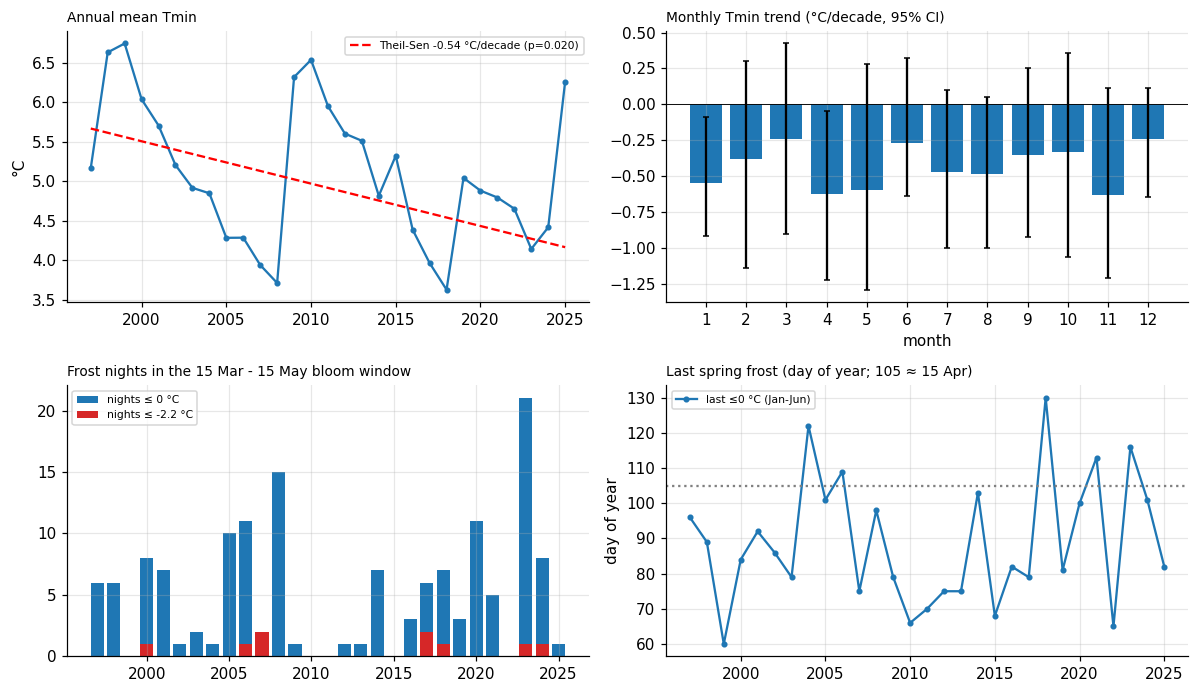

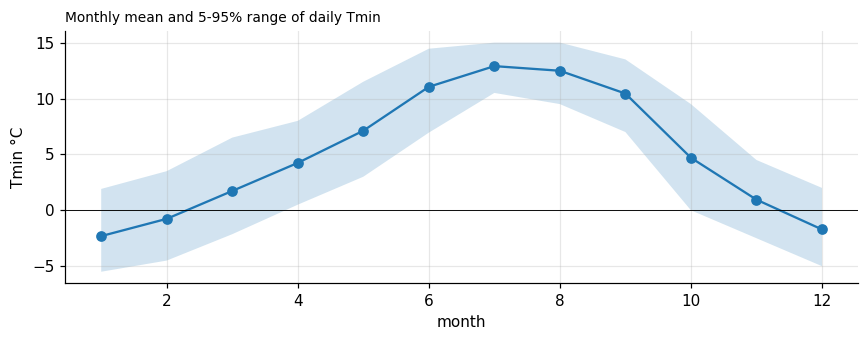

In [ ]:
yy=y[(y.index.year>=1997)&(y.index.year<=2025)]; yrs=np.arange(1997,2026)
def trend(vals,yrs_=yrs):
    ts=stats.theilslopes(vals,yrs_); kt=stats.kendalltau(yrs_,vals); return {'slope_per_decade':float(ts[0]*10),'lo':float(ts[2]*10),'hi':float(ts[3]*10),'p':float(kt.pvalue)}
def pettitt(vals):
    nn=len(vals); U=np.array([np.sum(np.sign(vals[t+1:][None,:]-vals[:t+1][:,None])) for t in range(nn-1)]); K=np.max(np.abs(U)); t=int(np.argmax(np.abs(U))); return t,float(min(1,2*np.exp(-6*K**2/(nn**3+nn**2))))
ann=yy.groupby(yy.index.year).mean().values; RES['annual_mean']=dict(zip(map(int,yrs),map(float,ann))); RES['trend_annual']=trend(ann)
t_idx,pp=pettitt(ann); RES['pettitt_annual']={'change_after_year':int(yrs[t_idx]),'p':pp,'mean_before':float(ann[:t_idx+1].mean()),'mean_after':float(ann[t_idx+1:].mean())}
mt={}
for m_ in range(1,13):
    s_=yy[yy.index.month==m_]; mt[m_]=trend(s_.groupby(s_.index.year).mean().values)
RES['trend_monthly']=mt
inw_all=((mo==3)&(dayv>=15))|(mo==4)|((mo==5)&(dayv<=15)); ys=pd.Series(yv,index=idx)
wm={};
for yr in yrs:
    w=ys[(ys.index.year==yr)&inw_all]; wm[yr]={'mean':float(w.mean()),'min':float(w.min()),'n0':int((w<=0).sum()),'n_m1':int((w<=-1).sum()),'n_m22':int((w<=-2.2).sum())}
RES['window_by_year']={int(k):v for k,v in wm.items()}
for key in ['mean','n0','n_m22','min']: RES['trend_window_'+key]=trend(np.array([wm[yr][key] for yr in yrs]))
# last spring frost (<=0 °C) and first autumn frost, frost-free season
lastf=[];firstf=[]
for yr in yrs:
    s1=ys[(ys.index>=f'{yr}-01-01')&(ys.index<=f'{yr}-06-30')]; lastf.append(s1[s1<=0].index[-1].dayofyear)
    s2=ys[(ys.index>=f'{yr}-08-01')&(ys.index<=f'{yr}-12-31')]; firstf.append(s2[s2<=0].index[0].dayofyear)
lastf=np.array(lastf); firstf=np.array(firstf); RES['last_spring_frost_doy']=dict(zip(map(int,yrs),map(int,lastf))); RES['first_autumn_frost_doy']=dict(zip(map(int,yrs),map(int,firstf)))
RES['trend_last_frost']=trend(lastf); RES['trend_first_frost']=trend(firstf); RES['trend_ffs']=trend(firstf-lastf)
RES['last_frost_mean_doy']=float(lastf.mean()); RES['last_frost_latest']=[int(yrs[lastf.argmax()]),int(lastf.max())]
nfd=np.array([int((yy[yy.index.year==yr]<=0).sum()) for yr in yrs]); RES['frost_days_year']=dict(zip(map(int,yrs),map(int,nfd))); RES['trend_frost_days']=trend(nfd)
# Mean winter (Dec-Feb) Tmin trend and mean spring Tmin
print({k:RES[k] for k in ['trend_annual','pettitt_annual','trend_window_mean','trend_window_n0','trend_window_n_m22','trend_last_frost','trend_frost_days']})
fig,ax=plt.subplots(2,2,figsize=(11,6.4))
a=ax[0,0]; a.plot(yrs,ann,'o-',ms=3); a.plot(yrs,np.median(ann)+0*yrs,alpha=0); ts=stats.theilslopes(ann,yrs); a.plot(yrs,ts[1]+ts[0]*yrs,'r--',label=f"Theil-Sen {ts[0]*10:+.2f} °C/decade (p={RES['trend_annual']['p']:.3f})"); a.legend(fontsize=7); a.set_title('Annual mean Tmin',fontsize=9,loc='left'); a.set_ylabel('°C')
a=ax[0,1]; a.bar(range(1,13),[mt[m]['slope_per_decade'] for m in range(1,13)],yerr=[[mt[m]['slope_per_decade']-mt[m]['lo'] for m in range(1,13)],[mt[m]['hi']-mt[m]['slope_per_decade'] for m in range(1,13)]],capsize=2); a.axhline(0,color='k',lw=.6); a.set_xticks(range(1,13)); a.set_title('Monthly Tmin trend (°C/decade, 95% CI)',fontsize=9,loc='left'); a.set_xlabel('month')
a=ax[1,0]; a.bar(yrs,[wm[yr]['n0'] for yr in yrs],label='nights ≤ 0 °C'); a.bar(yrs,[wm[yr]['n_m22'] for yr in yrs],color='C3',label='nights ≤ -2.2 °C'); a.legend(fontsize=7); a.set_title('Frost nights in the 15 Mar - 15 May bloom window',fontsize=9,loc='left')
a=ax[1,1]; a.plot(yrs,lastf,'o-',ms=3,label='last ≤0 °C (Jan-Jun)'); a.set_ylabel('day of year'); a.axhline(105,color='grey',ls=':'); a.set_title('Last spring frost (day of year; 105 ≈ 15 Apr)',fontsize=9,loc='left'); a.legend(fontsize=7)
savefig('fig12_patterns')
# Monthly climatology figure
fig,ax=plt.subplots(figsize=(8,3.2)); clim=pd.DataFrame({'m':mo,'t':yv}).groupby('m').t.agg(['mean',lambda s:s.quantile(.05),lambda s:s.quantile(.95)]); ax.plot(clim.index,clim['mean'],'o-'); ax.fill_between(clim.index,clim.iloc[:,1],clim.iloc[:,2],alpha=.2); ax.axhline(0,color='k',lw=.6); ax.set_xlabel('month'); ax.set_ylabel('Tmin °C'); ax.set_title('Monthly mean and 5-95% range of daily Tmin',fontsize=9,loc='left'); savefig('fig13_monthly')
RES['monthly_clim']={int(k):{'mean':float(r['mean']),'p5':float(r.iloc[1]),'p95':float(r.iloc[2])} for k,r in clim.iterrows()}

In [ ]:
# ---------- OPTIONAL: your own apple yield data (not supplied with the workbook, so nothing is computed unless you add a file) ----------
# Create 'apple_yield.csv' with columns: year,yield  (e.g. kg per tree or t/ha), upload it to Colab next to the notebook, and re-run this cell.
YIELD_FILE='apple_yield.csv'
if os.path.exists(YIELD_FILE):
    ay=pd.read_csv(YIELD_FILE).set_index('year')['yield']; ind=pd.DataFrame({k:[wm[yr][k] for yr in yrs] for k in ['n0','n_m22','mean']},index=yrs).join(ay,how='inner')
    print(ind.corr(method='spearman')['yield'].round(2)); print('n years =',len(ind))
else:
    print('No yield file found -> no yield analysis performed (none was provided with the data).')

No yield file found -> no yield analysis performed (none was provided with the data).


In [ ]:
# ---------- OPTIONAL: convert the cost-loss result to money (fill in YOUR orchard numbers) ----------
COST_PROTECT_NPR=None      # cost of protecting the orchard for ONE night (fuel, labour, covers ...)
LOSS_NPR=None              # loss if a damaging frost hits an unprotected orchard
if COST_PROTECT_NPR and LOSS_NPR:
    c=COST_PROTECT_NPR/LOSS_NPR; k=min(CRATIOS,key=lambda z:abs(z-c)); print('Nearest tabulated C/L =',k)
    for tk in THETAS:
        r=DEC[tk]['by_c'][str(k)]; print(tk,{nm:round(r[nm]*LOSS_NPR) for nm in ['never','always','ARIMA','LSTM','Interval-95 (raw)','perfect']})
else:
    print('Set COST_PROTECT_NPR and LOSS_NPR to translate the table (units of L) into Nepali rupees.')

Set COST_PROTECT_NPR and LOSS_NPR to translate the table (units of L) into Nepali rupees.


In [ ]:
# ---------- export ----------
tab=pd.DataFrame({nm:{f'{s}_{k}':v for s in ('val','test') for k,v in TABLE[nm][s].items()} for nm in TABLE}).T; tab.to_csv('model_metrics.csv'); print(tab.round(3).to_string())
RES['table']=TABLE
def clean(o):
    if isinstance(o,dict): return {str(k):clean(v) for k,v in o.items()}
    if isinstance(o,(list,tuple)): return [clean(v) for v in o]
    if isinstance(o,(np.floating,)): return float(o)
    if isinstance(o,(np.integer,)): return int(o)
    return o
json.dump(clean(RES),open('results.json','w'),indent=1)
imp.to_excel('thakmarpha_tmin_imputed.xlsx'); print('saved: results.json, model_metrics.csv, thakmarpha_tmin_imputed.xlsx/csv, figures/')

                               val_RMSE  val_MAE  val_MAPE_K  val_R2  test_RMSE  test_MAE  test_MAPE_K  test_R2
Persistence (y[t-1])              1.906    1.364       0.494   0.891      1.717     1.224        0.442    0.917
Climatology (harmonic, train)     2.147    1.699       0.615   0.862      2.142     1.686        0.608    0.871
MA(6) on raw                      2.184    1.672       0.605   0.857      2.028     1.555        0.560    0.885
AR(3) on raw                      1.734    1.280       0.463   0.910      1.571     1.152        0.415    0.931
MA(6) on adjusted                 1.684    1.258       0.455   0.915      1.557     1.152        0.415    0.932
AR(3) on adjusted                 1.661    1.235       0.447   0.917      1.519     1.121        0.404    0.935
ARIMA(2,1,3) on adjusted          1.631    1.208       0.437   0.920      1.510     1.123        0.405    0.936
ARIMA(3,1,3) on raw               1.686    1.237       0.447   0.915      1.553     1.152        0.415  